# 01 — EDA: Thống kê dữ liệu PhoNER_COVID19

**Người phụ trách:** Đạt

Notebook này chỉ là "trạm chạy": mọi logic đọc dữ liệu nằm trong `src/data/`. Nội dung:
1. Tải dữ liệu (mức từ và mức âm tiết) bằng `src.data.download`.
2. Số câu, số token, độ dài câu của từng tập.
3. Phân bố 10 loại thực thể, tỉ lệ nhãn `O`, độ dài thực thể.
4. Tỉ lệ từ ngoài từ điển (OOV) của dev/test so với train (giải thích vì sao cần character embedding).
5. Xuất bảng `.csv/.json` vào `outputs/metrics/` và hình (đọc được ở thang xám) vào `outputs/figures/`.

> Bảng/hình ở đây là **thống kê dữ liệu thật**, không phải kết quả mô hình, nên dùng trực tiếp trong Proposal và mục Dữ liệu của báo cáo.

In [1]:
# Cell thiết lập: chạy được cả trên Kaggle, Colab và máy cá nhân.
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/TTins1702/NER-PhoNER_COVID19-UET.git"
REPO_NAME = "NER-PhoNER_COVID19-UET"
IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = "KAGGLE_KERNEL_RUN_TYPE" in os.environ

if IN_COLAB or IN_KAGGLE:
    base = Path("/kaggle/working") if IN_KAGGLE else Path("/content")
    ROOT = base / REPO_NAME
    if not (ROOT / ".git").exists():
        subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
    else:
        subprocess.run(["git", "-C", str(ROOT), "pull"], check=True)
else:
    # Máy cá nhân: đi ngược lên tới thư mục chứa src/
    ROOT = Path.cwd()
    while not (ROOT / "src").is_dir() and ROOT.parent != ROOT:
        ROOT = ROOT.parent

os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Thư mục làm việc:", ROOT)


Thư mục làm việc: C:\Users\ThinkPad\Downloads\NER-PhoNER_COVID19-UET


In [2]:
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from src.data.download import download_phoner_covid19, load_split, LEVELS, SPLITS
from src.data.labels import ENTITY_TYPES, SHORT_NAMES, display_name, extract_entities
from src.data.vocab import WordVocab

DATA_DIR = Path("data")
METRICS_DIR = Path("outputs/metrics"); METRICS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

# Kiểu hình thống nhất cho báo cáo ACL: chữ 9-10pt, chỉ dùng thang xám + hoa văn (hatch).
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "figure.dpi": 120,
                     "savefig.bbox": "tight", "pdf.fonttype": 42})
GRAYS = ["0.15", "0.55", "0.85"]
HATCHES = ["", "///", "..."]

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=200)
    print("Đã lưu", FIG_DIR / f"{name}.pdf")

download_phoner_covid19(DATA_DIR)
data = {level: {split: load_split(split, level, DATA_DIR) for split in SPLITS} for level in LEVELS}

[download] 'data' đã có đủ dữ liệu. Bỏ qua (dùng --force để tải lại).


## 1. Số câu, số token, độ dài câu

In [3]:
rows = []
for level in LEVELS:
    for split in SPLITS:
        samples = data[level][split]
        lens = np.array([len(s["words"]) for s in samples])
        tags = [t for s in samples for t in s["tags"]]
        n_ent = sum(len(extract_entities(s["tags"])) for s in samples)
        rows.append({
            "level": level, "split": split, "sentences": len(samples), "tokens": int(lens.sum()),
            "len_mean": round(float(lens.mean()), 2), "len_median": float(np.median(lens)),
            "len_p95": float(np.percentile(lens, 95)), "len_max": int(lens.max()),
            "entities": n_ent, "O_ratio_%": round(100 * sum(t == "O" for t in tags) / len(tags), 2),
            "sent_without_entity_%": round(100 * np.mean([all(t == "O" for t in s["tags"]) for s in samples]), 2),
        })
split_stats = pd.DataFrame(rows)
split_stats.to_csv(METRICS_DIR / "data_split_stats.csv", index=False)
split_stats

,level,split,sentences,tokens,len_mean,len_median,len_p95,len_max,entities,O_ratio_%,sent_without_entity_%
0,word,train,5027,132511,26.36,24.0,50.0,161,15767,79.05,8.37
1,word,dev,2000,56283,28.14,25.0,54.0,138,7478,74.92,4.70
2,word,test,3000,85678,28.56,26.0,55.0,162,11735,74.17,3.80
3,syllable,train,5027,167541,33.33,30.0,64.0,186,15767,77.22,8.37
4,syllable,dev,2000,71325,35.66,32.0,68.0,182,7478,72.50,4.70
5,syllable,test,3000,108354,36.12,32.0,68.0,185,11735,71.78,3.80


## 2. Phân bố 10 loại thực thể (đếm theo **thực thể**, không theo token)

In [4]:
def entity_counts(samples):
    c = Counter(etype for s in samples for etype, _, _ in extract_entities(s["tags"]))
    return [c.get(t, 0) for t in ENTITY_TYPES]

ent_df = pd.DataFrame({split: entity_counts(data["word"][split]) for split in SPLITS},
                      index=[display_name(t) for t in ENTITY_TYPES])
ent_df["total"] = ent_df.sum(axis=1)
ent_df.loc["TOTAL"] = ent_df.sum()
ent_df = ent_df.astype(int)
ent_df["share_%"] = (100 * ent_df["total"] / ent_df.loc["TOTAL", "total"]).round(2)
ent_df.to_csv(METRICS_DIR / "data_entity_counts_word.csv")
ent_df

,train,dev,test,total,share_%
AGE,682,361,582,1625,4.65
DATE,2549,1103,1654,5306,15.17
GENDER,542,277,462,1281,3.66
OCCUPATION,205,132,173,510,1.46
LOCATION,5398,2737,4441,12576,35.95
PERSON_NAME,349,188,318,855,2.44
ORGANIZATION,1137,551,771,2459,7.03
PATIENT_ID,3240,1276,2005,6521,18.64
SYMPTOM_AND_DISEASE,1439,766,1136,3341,9.55
TRANSPORTATION,226,87,193,506,1.45


In [5]:
# Kiểm tra: số thực thể ở mức từ và mức âm tiết phải bằng nhau (chỉ khác cách tách token)
ent_syl = pd.DataFrame({split: entity_counts(data["syllable"][split]) for split in SPLITS},
                       index=[display_name(t) for t in ENTITY_TYPES])
print("Chênh lệch số thực thể word - syllable:")
print((ent_df.loc[ent_syl.index, list(SPLITS)] - ent_syl).abs().sum().to_dict())

Chênh lệch số thực thể word - syllable:
{'train': 0, 'dev': 0, 'test': 0}


Đã lưu outputs\figures\eda_entity_distribution.pdf


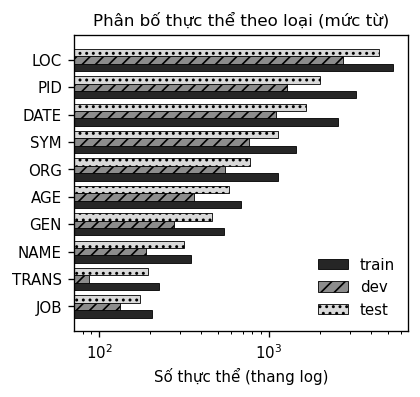

In [6]:
fig, ax = plt.subplots(figsize=(3.6, 3.2))
types_sorted = sorted(ENTITY_TYPES, key=lambda t: ent_df.loc[display_name(t), "train"])
y = np.arange(len(types_sorted)); h = 0.27
for k, split in enumerate(SPLITS):
    vals = [ent_df.loc[display_name(t), split] for t in types_sorted]
    ax.barh(y + (k - 1) * h, vals, height=h, color=GRAYS[k], hatch=HATCHES[k],
            edgecolor="black", linewidth=0.5, label=split)
ax.set_yticks(y); ax.set_yticklabels([SHORT_NAMES[t] for t in types_sorted])
ax.set_xscale("log"); ax.set_xlabel("Số thực thể (thang log)")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Phân bố thực thể theo loại (mức từ)")
save_fig(fig, "eda_entity_distribution")
plt.show()

## 3. Phân bố độ dài câu (mức từ vs mức âm tiết, tập train)

Đã lưu outputs\figures\eda_sentence_length.pdf


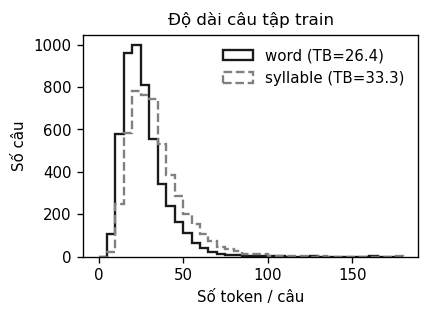

In [7]:
fig, ax = plt.subplots(figsize=(3.6, 2.4))
bins = np.arange(0, 181, 5)
for level, style, color in [("word", "-", "0.1"), ("syllable", "--", "0.5")]:
    lens = [len(s["words"]) for s in data[level]["train"]]
    ax.hist(lens, bins=bins, histtype="step", linestyle=style, color=color, linewidth=1.4,
            label=f"{level} (TB={np.mean(lens):.1f})")
ax.set_xlabel("Số token / câu"); ax.set_ylabel("Số câu")
ax.legend(frameon=False)
ax.set_title("Độ dài câu tập train")
save_fig(fig, "eda_sentence_length")
plt.show()

## 4. Độ dài thực thể (số token) theo loại

In [8]:
rows = []
for level in LEVELS:
    spans = {t: [] for t in ENTITY_TYPES}
    for s in data[level]["train"]:
        for etype, st, en in extract_entities(s["tags"]):
            spans[etype].append(en - st)
    for t in ENTITY_TYPES:
        arr = np.array(spans[t])
        rows.append({"level": level, "type": display_name(t), "mean_len": round(float(arr.mean()), 2),
                     "max_len": int(arr.max()), "single_token_%": round(100 * float((arr == 1).mean()), 1)})
ent_len = pd.DataFrame(rows).pivot(index="type", columns="level", values=["mean_len", "max_len", "single_token_%"])
ent_len.to_csv(METRICS_DIR / "data_entity_length.csv")
ent_len

mean_len        max_len       single_token_%       
level               syllable  word syllable  word       syllable   word
type                                                                   
AGE                     1.00  1.00      2.0   2.0           99.7   99.7
DATE                    1.98  1.98      5.0   5.0           50.9   50.9
GENDER                  1.03  1.00      2.0   1.0           97.4  100.0
LOCATION                3.28  1.97     21.0  13.0            8.0   44.1
OCCUPATION              2.55  1.30      6.0   4.0            1.0   80.0
ORGANIZATION            5.24  3.24     17.0  14.0            1.7    4.4
PATIENT_ID              1.00  1.00      9.0   5.0           99.8   99.8
PERSON_NAME             1.23  1.04      4.0   2.0           87.4   96.3
SYMPTOM_AND_DISEASE     2.58  2.08     11.0   7.0           23.8   33.6
TRANSPORTATION          1.31  1.30      4.0   4.0           74.8   74.8

## 5. Tỉ lệ OOV so với từ điển train

`WordVocab` **chỉ xây từ train** (tránh rò rỉ dữ liệu), nên từ của dev/test không có trong train sẽ thành `<unk>`.
Tỉ lệ OOV trong **token thực thể** cho biết loại nào phụ thuộc nhiều vào character embedding / ngữ cảnh.

In [9]:
rows = []
for level in LEVELS:
    for min_freq in (1, 2):
        vocab = WordVocab.build([s["words"] for s in data[level]["train"]], min_freq=min_freq)
        for split in ("dev", "test"):
            samples = data[level][split]
            row = {"level": level, "min_freq": min_freq, "split": split, "vocab_size": len(vocab),
                   "oov_all_%": round(100 * vocab.oov_rate([s["words"] for s in samples]), 2)}
            for t in ENTITY_TYPES:
                toks = [s["words"][i] for s in samples for et, a, b in extract_entities(s["tags"])
                        if et == t for i in range(a, b)]
                row[f"oov_{SHORT_NAMES[t]}_%"] = round(100 * sum(w not in vocab for w in toks) / max(1, len(toks)), 1)
            rows.append(row)
oov_df = pd.DataFrame(rows)
oov_df.to_csv(METRICS_DIR / "data_oov.csv", index=False)
oov_df

,level,min_freq,split,vocab_size,oov_all_%,oov_AGE_%,oov_DATE_%,oov_GEN_%,oov_JOB_%,oov_LOC_%,oov_NAME_%,oov_ORG_%,oov_PID_%,oov_SYM_%,oov_TRANS_%
0,word,1,dev,5169,2.58,0.0,0.9,0.0,5.5,7.8,35.8,3.4,13.6,4.7,26.8
1,word,1,test,5169,2.96,0.2,1.2,0.0,8.7,8.2,38.4,4.1,14.7,6.5,34.7
2,word,2,dev,3274,4.07,0.0,2.0,0.0,12.2,11.0,45.6,4.8,23.5,8.7,36.6
3,word,2,test,3274,4.49,0.2,2.0,0.0,12.9,11.9,47.4,6.1,22.7,10.5,47.3
4,syllable,1,dev,3872,1.22,0.0,0.9,0.0,0.9,2.5,25.4,1.2,13.6,2.1,26.8
5,syllable,1,test,3872,1.46,0.2,1.2,0.0,2.5,2.6,28.6,1.4,14.7,2.9,34.0
6,syllable,2,dev,2770,2.03,0.0,2.0,0.0,2.9,3.6,32.9,1.8,23.5,4.8,36.6
7,syllable,2,test,2770,2.31,0.2,2.0,0.0,3.5,3.9,36.1,2.3,22.7,5.6,47.2


Đã lưu outputs\figures\eda_oov_by_type.pdf


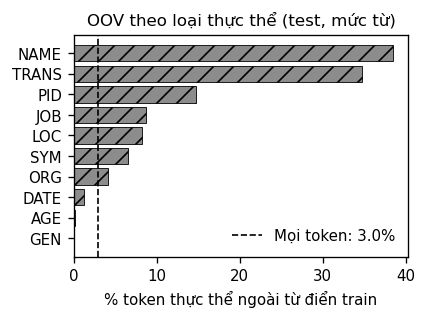

In [10]:
# Hình: OOV của token thực thể theo loại (mức từ, test, min_freq=1)
r = oov_df[(oov_df.level == "word") & (oov_df.min_freq == 1) & (oov_df.split == "test")].iloc[0]
vals = [r[f"oov_{SHORT_NAMES[t]}_%"] for t in ENTITY_TYPES]
order = np.argsort(vals)
fig, ax = plt.subplots(figsize=(3.6, 2.4))
ax.barh(np.arange(len(order)), [vals[i] for i in order], color="0.55", edgecolor="black", linewidth=0.5, hatch="//")
ax.set_yticks(np.arange(len(order))); ax.set_yticklabels([SHORT_NAMES[ENTITY_TYPES[i]] for i in order])
ax.axvline(r["oov_all_%"], color="black", linestyle="--", linewidth=1, label=f"Mọi token: {r['oov_all_%']:.1f}%")
ax.set_xlabel("% token thực thể ngoài từ điển train"); ax.legend(frameon=False, loc="lower right")
ax.set_title("OOV theo loại thực thể (test, mức từ)")
save_fig(fig, "eda_oov_by_type")
plt.show()

## 6. Kiểm tra tính hợp lệ BIO của nhãn gốc và ví dụ từng loại

In [11]:
from src.evaluation.metrics import bio_violation_stats
for level in LEVELS:
    for split in SPLITS:
        v = bio_violation_stats([s["tags"] for s in data[level][split]])
        print(f"{level:8s} {split:5s}: vi phạm BIO trong nhãn gốc = {v['total']}")

word     train: vi phạm BIO trong nhãn gốc = 0
word     dev  : vi phạm BIO trong nhãn gốc = 0
word     test : vi phạm BIO trong nhãn gốc = 0
syllable train: vi phạm BIO trong nhãn gốc = 0
syllable dev  : vi phạm BIO trong nhãn gốc = 0
syllable test : vi phạm BIO trong nhãn gốc = 0


In [12]:
examples = {}
for s in data["word"]["train"]:
    for etype, a, b in extract_entities(s["tags"]):
        examples.setdefault(etype, Counter())[" ".join(s["words"][a:b])] += 1
pd.DataFrame({display_name(t): [", ".join(w for w, _ in examples[t].most_common(5))] for t in ENTITY_TYPES},
             index=["5 cụm phổ biến nhất (train)"]).T

,5 cụm phổ biến nhất (train)
AGE,"26, 30, 55, 64, 63"
DATE,"27/7, 25/7, 25 - 7, 31/7, 24 - 7"
GENDER,"nữ, nam, Nữ, Nam, gái"
OCCUPATION,"phi_công, điều_dưỡng, du_học_sinh, lái_xe, tiế..."
LOCATION,"Đà_Nẵng, Hà_Nội, Việt_Nam, Bệnh_viện Đà_Nẵng, ..."
PERSON_NAME,"T., N.H.N., Nhung, Nguyễn_Hồng_Nhung, H."
ORGANIZATION,"Bộ Y_tế, Viện Vệ_sinh Dịch_tễ Trung_ương, Viện..."
PATIENT_ID,"17, 91, 416, 243, 34"
SYMPTOM_AND_DISEASE,"sốt, ho, khó thở, tăng huyết_áp, viêm phổi"
TRANSPORTATION,"VN54, VN0054, VN 0054, VN0062, SU 290"


## 7. Lưu tóm tắt JSON (nhẹ, commit được)

In [13]:
summary = {
    "split_stats": split_stats.to_dict(orient="records"),
    "entity_counts_word": ent_df.drop(columns=["share_%"]).astype(int).to_dict(),
    "oov": oov_df.to_dict(orient="records"),
}
with open(METRICS_DIR / "data_stats.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)
print("Đã lưu", METRICS_DIR / "data_stats.json")

Đã lưu outputs\metrics\data_stats.json
